# Bubble Chart

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

A scatter plot whose marker area encodes a third numeric variable. Three measures fit in one view, with the size channel adding emphasis.

## When to use

- Show three numeric variables at once (x, y, and size)
- Show entities whose size or weight matters (population, revenue)
- Tell a 'Gapminder-style' story about countries or companies

## Avoid when

- Precise comparison of the third variable matters (area is judged poorly)
- There are many bubbles that overlap heavily
- Sizes span several orders of magnitude without scaling

## Alternatives

- Scatter plot with color for a third variable
- Small multiples

## Design tips

- Scale bubble *area*, not radius, to the value
- Add a size legend with two or three reference bubbles
- Draw large bubbles first so small ones remain visible on top

## Example

GDP per capita vs. life expectancy for 40 fictional countries; bubble area = population.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(8)
n = 40
gdp = np.exp(rng.uniform(np.log(800), np.log(80000), n))
life = 48 + 7.5 * np.log10(gdp) + rng.normal(0, 2.5, n)
pop = np.exp(rng.normal(3, 1.3, n))          # millions
region = rng.choice(["Asia", "Africa", "Europe"], n, p=[0.4, 0.35, 0.25])
df = pd.DataFrame({"country": [f"C{i:02d}" for i in range(n)], "gdp_pc": gdp,
                   "life_exp": life, "pop_m": pop, "region": region})
df = df.sort_values("pop_m", ascending=False)   # big bubbles drawn first
df.head()

,country,gdp_pc,life_exp,pop_m,region
0,C00,3606.073216,77.646340,450.840103,Africa
27,C27,4894.534648,74.624392,284.893758,Europe
4,C04,43942.322830,82.822073,213.583155,Asia
38,C38,43365.037438,81.192285,183.331575,Asia
2,C02,3471.455991,70.777144,103.408540,Asia


### Plot

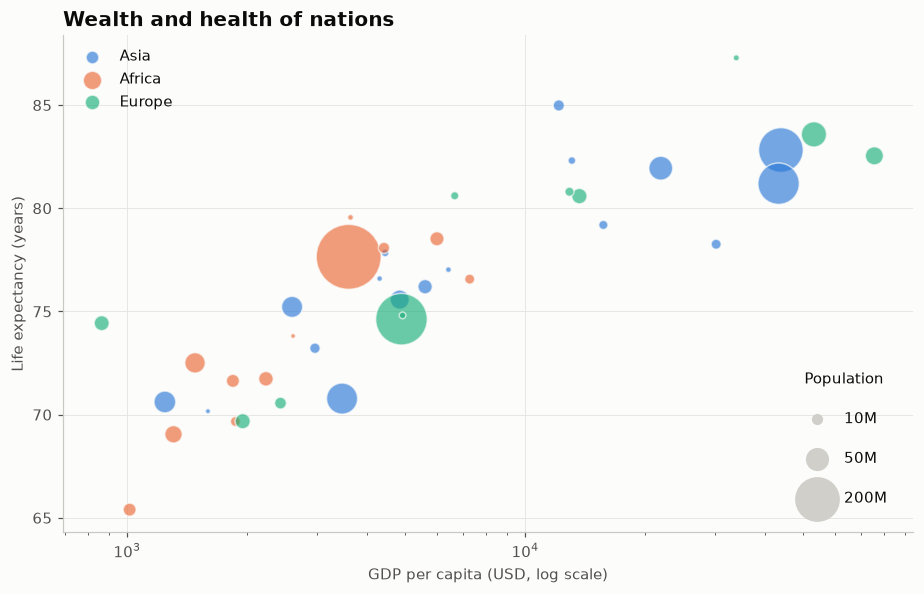

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
size = lambda p: p * 4                         # area proportional to population
for color, reg in zip(PALETTE, ["Asia", "Africa", "Europe"]):
    g = df[df["region"] == reg]
    ax.scatter(g["gdp_pc"], g["life_exp"], s=size(g["pop_m"]), color=color,
               alpha=0.65, edgecolor="#fcfcfb", linewidth=1, label=reg)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (USD, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("Wealth and health of nations")
leg1 = ax.legend(loc="upper left", markerscale=0.4)
ax.add_artist(leg1)
for p in [10, 50, 200]:
    ax.scatter([], [], s=size(p), color="#d0cfca", label=f"{p}M")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[3:], labels[3:], loc="lower right", title="Population",
          labelspacing=1.6, borderpad=1.2)
fig.tight_layout()
plt.show()

## How to read it

Position shows wealth (x) and health (y). Bubble area shows population. Richer countries live longer, with diminishing returns, which is why the x-axis is logarithmic.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.scatter(df, x="gdp_pc", y="life_exp", size="pop_m", color="region", hover_name="country",
                 log_x=True, size_max=45, color_discrete_sequence=PALETTE,
                 category_orders={"region": ["Asia", "Africa", "Europe"]},
                 labels={"gdp_pc": "GDP per capita (USD, log scale)", "life_exp": "Life expectancy (years)",
                         "pop_m": "Population (M)", "region": "Region"},
                 title="Wealth and health of nations")
fig.update_traces(marker=dict(opacity=0.7, line=dict(color="#fcfcfb", width=1)))
fig.show()

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder 2007 (Asia, Africa, Europe), bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
gm = px.data.gapminder().query("year == 2007 and continent in ['Asia', 'Africa', 'Europe']")
df = pd.DataFrame({"country": gm["country"], "gdp_pc": gm["gdpPercap"], "life_exp": gm["lifeExp"],
                   "pop_m": gm["pop"] / 1e6, "region": gm["continent"]})
df = df.sort_values("pop_m", ascending=False)
df.head()

,country,gdp_pc,life_exp,pop_m,region
299,China,4959.114854,72.961,1318.683096,Asia
707,India,2452.210407,64.698,1110.396331,Asia
719,Indonesia,3540.651564,70.650,223.547000,Asia
1175,Pakistan,2605.947580,65.483,169.270617,Asia
107,Bangladesh,1391.253792,64.062,150.448339,Asia


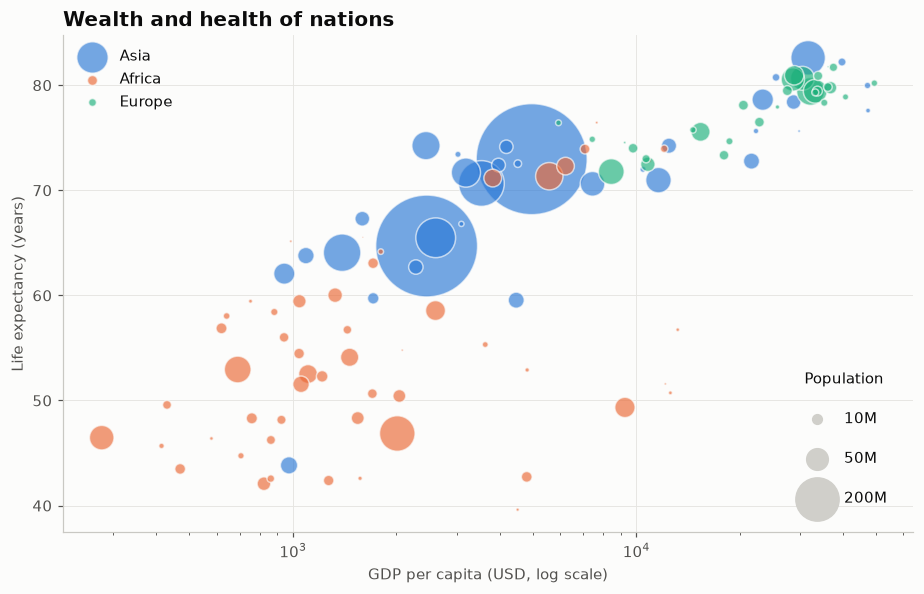

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
size = lambda p: p * 4                         # area proportional to population
for color, reg in zip(PALETTE, ["Asia", "Africa", "Europe"]):
    g = df[df["region"] == reg]
    ax.scatter(g["gdp_pc"], g["life_exp"], s=size(g["pop_m"]), color=color,
               alpha=0.65, edgecolor="#fcfcfb", linewidth=1, label=reg)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (USD, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("Wealth and health of nations")
leg1 = ax.legend(loc="upper left", markerscale=0.4)
ax.add_artist(leg1)
for p in [10, 50, 200]:
    ax.scatter([], [], s=size(p), color="#d0cfca", label=f"{p}M")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[3:], labels[3:], loc="lower right", title="Population",
          labelspacing=1.6, borderpad=1.2)
fig.tight_layout()
plt.show()

---
Standalone script: [`bubble.py`](bubble.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)